In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
from src.data_loader import load_pjm_data

df = load_pjm_data("../data/raw/PJME_hourly.csv")
df.head()

,PJME_MW
2002-01-01 01:00:00,30393.0
2002-01-01 02:00:00,29265.0
2002-01-01 03:00:00,28357.0
2002-01-01 04:00:00,27899.0
2002-01-01 05:00:00,28057.0


In [2]:
df["hour"] = df.index.hour
df["day_of_week"] = df.index.dayofweek       # Monday=0 ... Sunday=6
df["month"] = df.index.month
df["is_weekend"] = (df.index.dayofweek >= 5).astype(int)

df[["hour", "day_of_week", "month", "is_weekend"]].head()

,hour,day_of_week,month,is_weekend
2002-01-01 01:00:00,1,1,1,0
2002-01-01 02:00:00,2,1,1,0
2002-01-01 03:00:00,3,1,1,0
2002-01-01 04:00:00,4,1,1,0
2002-01-01 05:00:00,5,1,1,0


In [3]:
df["lag_1"] = df["PJME_MW"].shift(1)
df["lag_2"] = df["PJME_MW"].shift(2)
df["lag_24"] = df["PJME_MW"].shift(24)
df["lag_168"] = df["PJME_MW"].shift(168)  # same hour, 1 week ago

df[["PJME_MW", "lag_1", "lag_2", "lag_24", "lag_168"]].head(3)

,PJME_MW,lag_1,lag_2,lag_24,lag_168
2002-01-01 01:00:00,30393.0,NaN,NaN,NaN,NaN
2002-01-01 02:00:00,29265.0,30393.0,NaN,NaN,NaN
2002-01-01 03:00:00,28357.0,29265.0,30393.0,NaN,NaN


In [4]:
df["rolling_mean_24"] = df["PJME_MW"].shift(1).rolling(window=24).mean()
df["rolling_std_24"] = df["PJME_MW"].shift(1).rolling(window=24).std()

df[["PJME_MW", "rolling_mean_24", "rolling_std_24"]].head(30)

,PJME_MW,rolling_mean_24,rolling_std_24
2002-01-01 01:00:00,30393.0,NaN,NaN
2002-01-01 02:00:00,29265.0,NaN,NaN
2002-01-01 03:00:00,28357.0,NaN,NaN
2002-01-01 04:00:00,27899.0,NaN,NaN
2002-01-01 05:00:00,28057.0,NaN,NaN
2002-01-01 06:00:00,28654.0,NaN,NaN
2002-01-01 07:00:00,29308.0,NaN,NaN
2002-01-01 08:00:00,29595.0,NaN,NaN
2002-01-01 09:00:00,29943.0,NaN,NaN
2002-01-01 10:00:00,30692.0,NaN,NaN


In [5]:
df_features = df.dropna()
print(f"Rows before dropping: {len(df)}")
print(f"Rows after dropping: {len(df_features)}")
print(f"Rows dropped: {len(df) - len(df_features)}")


Rows before dropping: 145392
Rows after dropping: 145224
Rows dropped: 168


In [6]:
from sklearn.model_selection import TimeSeriesSplit

df_model = df_features.loc["2016-01-01":].copy()
print(df_model.shape)

(22681, 11)


In [7]:
tscv = TimeSeriesSplit(n_splits=5, test_size=24*30)  # 5 splits, each test window = 30 days

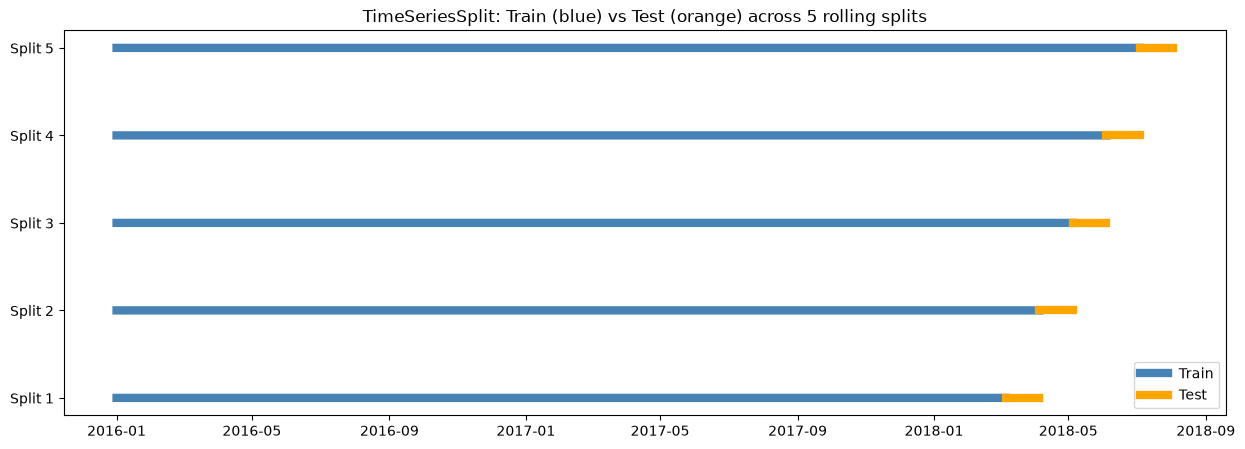

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(15, 5))

for i, (train_idx, test_idx) in enumerate(tscv.split(df_model)):
    ax.plot(df_model.index[train_idx], [i] * len(train_idx), 
             color="steelblue", linewidth=6, label="Train" if i == 0 else "")
    ax.plot(df_model.index[test_idx], [i] * len(test_idx), 
             color="orange", linewidth=6, label="Test" if i == 0 else "")

ax.set_yticks(range(5))
ax.set_yticklabels([f"Split {i+1}" for i in range(5)])
ax.set_title("TimeSeriesSplit: Train (blue) vs Test (orange) across 5 rolling splits")
ax.legend()
plt.show()

In [9]:
feature_cols = [
    "hour", "day_of_week", "month", "is_weekend",
    "lag_1", "lag_2", "lag_24", "lag_168",
    "rolling_mean_24", "rolling_std_24"
]

X = df_model[feature_cols]
y = df_model["PJME_MW"]

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

fold_results = []

for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    model = LinearRegression()
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))

    fold_results.append({"fold": fold + 1, "MAE": mae, "RMSE": rmse})
    print(f"Fold {fold+1}: MAE={mae:.2f}, RMSE={rmse:.2f}")

fold_results_df = pd.DataFrame(fold_results)
print("\nAverage across folds:")
print(fold_results_df[["MAE", "RMSE"]].mean())

Fold 1: MAE=431.81, RMSE=591.03
Fold 2: MAE=416.74, RMSE=586.31
Fold 3: MAE=391.16, RMSE=507.32
Fold 4: MAE=393.97, RMSE=514.12
Fold 5: MAE=394.86, RMSE=506.65

Average across folds:
MAE     405.707687
RMSE    541.087839
dtype: float64


In [11]:
from sklearn.ensemble import RandomForestRegressor

fold_results_rf = []

for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    model_rf = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
    model_rf.fit(X_train, y_train)
    preds = model_rf.predict(X_test)

    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))

    fold_results_rf.append({"fold": fold + 1, "MAE": mae, "RMSE": rmse})
    print(f"Fold {fold+1}: MAE={mae:.2f}, RMSE={rmse:.2f}")

fold_results_rf_df = pd.DataFrame(fold_results_rf)
print("\nAverage across folds:")
print(fold_results_rf_df[["MAE", "RMSE"]].mean())

Fold 1: MAE=258.76, RMSE=358.74
Fold 2: MAE=222.71, RMSE=307.63
Fold 3: MAE=238.80, RMSE=318.99
Fold 4: MAE=296.41, RMSE=402.40
Fold 5: MAE=292.10, RMSE=393.27

Average across folds:
MAE     261.757026
RMSE    356.207252
dtype: float64


In [12]:
from xgboost import XGBRegressor

fold_results_xgb = []

for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    model_xgb = XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        random_state=42,
        n_jobs=-1
    )
    model_xgb.fit(X_train, y_train)
    preds = model_xgb.predict(X_test)

    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))

    fold_results_xgb.append({"fold": fold + 1, "MAE": mae, "RMSE": rmse})
    print(f"Fold {fold+1}: MAE={mae:.2f}, RMSE={rmse:.2f}")

fold_results_xgb_df = pd.DataFrame(fold_results_xgb)
print("\nAverage across folds:")
print(fold_results_xgb_df[["MAE", "RMSE"]].mean())

Fold 1: MAE=239.50, RMSE=322.83
Fold 2: MAE=219.97, RMSE=283.28
Fold 3: MAE=226.55, RMSE=303.66
Fold 4: MAE=287.20, RMSE=452.71
Fold 5: MAE=285.91, RMSE=397.80

Average across folds:
MAE     251.825258
RMSE    352.057018
dtype: float64


In [13]:
importances = pd.Series(model_xgb.feature_importances_, index=feature_cols)
importances = importances.sort_values(ascending=False)
print(importances)

lag_1              0.949690
lag_2              0.020829
hour               0.016222
rolling_mean_24    0.004406
day_of_week        0.003407
rolling_std_24     0.002038
lag_24             0.001536
month              0.001416
lag_168            0.000456
is_weekend         0.000000
dtype: float32
